### COSTANTI

In [76]:
#tutte le costanti utili in un unico posto :)
import numpy as np


BATCH_SIZE = 256

# ImageNet normalization statistics
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)

## ⚙️ **Libraries Import**

In [77]:
# Set seed for reproducibility
SEED = 100

# Import necessary libraries
import os

# Set environment variables before importing modules
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['MPLCONFIGDIR'] = os.getcwd() + '/configs/'

# Suppress warnings
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=Warning)

# Import necessary modules
import logging
import random
from pathlib import Path


# Set seeds for random number generators in NumPy and Python
np.random.seed(SEED)
random.seed(SEED)

# Import PyTorch
import torch
torch.manual_seed(SEED)
from torch import nn
from torchsummary import summary
#from torch.utils.tensorboard import SummaryWriter
import torchvision
from torchvision.transforms import v2 as transforms
from torch.utils.data import TensorDataset, DataLoader
#!pip install torchview
#from torchview import draw_graph

# Configurazione di TensorBoard e directory
#logs_dir = "tensorboard"
#!pkill -f tensorboard
#%load_ext tensorboard
#!mkdir -p models

if torch.cuda.is_available():
    device = torch.device("cuda")
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
else:
    device = torch.device("cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")

# Import other libraries
import cv2
import copy
import shutil
from itertools import product
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.model_selection import train_test_split
from PIL import Image
import matplotlib.gridspec as gridspec
import requests
from io import BytesIO

# Configure plot display settings
sns.set(font_scale=1.4)
sns.set_style('white')
plt.rc('font', size=14)
%matplotlib inline

PyTorch version: 2.6.0+cu124
Device: cuda


## 🔧 **Automatic Configuration**

In [78]:
#(LOCAL vs KAGGLE)

def get_paths():
    """It detects the enviroment and returns the correct path."""
    if os.path.exists('/kaggle/input'):
        print("🌍 Detetected enviroment: KAGGLE")
        !ls "/kaggle/input/dataset"
        input_dir = Path('/kaggle/input/dataset/')
        output_dir = Path('/kaggle/working/')
    else:
        print("💻 Detetected enviroment: LOCAL")
        # Impostate la vostra cartella di input e output locali
        #input_dir = Path('../data/archive/')
        input_dir = Path('/home/michele/Scrivania/dataset/')
        #output_dir = Path('../data/output/')
        output_dir = Path('/home/michele/Scrivania/')

        # Crea le cartelle se non esistono in locale
        output_dir.mkdir(parents=True, exist_ok=True)

    return input_dir, output_dir

INPUT_DIR, OUTPUT_DIR = get_paths()
print(f"Input directory: {INPUT_DIR}")
print(f"Output directory: {OUTPUT_DIR}")


🌍 Detetected enviroment: KAGGLE
masks_cleaned.npy  test_images.npy  train_data	      train_labels.csv
test_data	   test_masks.npy   train_images.npy  train_masks.npy
Input directory: /kaggle/input/dataset
Output directory: /kaggle/working


In [79]:
#creo cartella per i models
models_dir=OUTPUT_DIR/'models'
models_dir.mkdir(parents=True, exist_ok=True)

## ⏳ **Data Loading**

In [80]:
def normalize_image(img, standardize=True):

    img = img.astype(np.float32)
    # Se i pixel non sono ancora in [0,1], li scala
    if img.max() > 1.0:
        img = img / 255.0

    if standardize:
        # Media e std ImageNet
        img = (img - IMAGENET_MEAN) / IMAGENET_STD

    return img

In [81]:
# I numpy sono nel dataset ora (MESSI SUCCESSIVAMENTE) 
train_images = np.load(INPUT_DIR/'train_images.npy')
train_masks = np.load(INPUT_DIR/'masks_cleaned.npy')
test_images = np.load(INPUT_DIR/'test_images.npy')
test_masks = np.load(INPUT_DIR/'test_masks.npy')
train_labels = pd.read_csv(INPUT_DIR/'train_labels.csv')

train_images=train_images.astype('float32')
train_masks=train_masks.astype('float32')
test_images=test_images.astype('float32')
test_masks=test_masks.astype('float32')

print(type(train_images))

# Get class names
class_names = train_labels['label']
#print(class_names)

print("Data loaded sucessfully!")
print(f"Train images shape: {train_images.shape}")
print(f"Train masks shape: {train_masks.shape}")
print(f"Test images shape: {test_images.shape}")
print(f"Test masks shape: {test_masks.shape}")
print(f"Train labels shape: {train_labels.shape}")

<class 'numpy.ndarray'>
Data loaded sucessfully!
Train images shape: (1252, 224, 224, 3)
Train masks shape: (1252, 224, 224, 1)
Test images shape: (954, 224, 224, 3)
Test masks shape: (954, 224, 224, 1)
Train labels shape: (1252, 2)


## 🔎 **Data Analysis**

In [82]:
#LABELS ANALYSIS AND DISTRIBUTION
print(train_labels.describe())

print("\n--- Unique Labels ---")
unique_labels = train_labels['label'].unique()
print(unique_labels)

print("\n--- Label Distribution ---")
label_counts = train_labels['label'].value_counts()
label_percentages = train_labels['label'].value_counts(normalize=True) * 100
label_stats = pd.DataFrame({
    'count': label_counts,
    'percentage': label_percentages
})
print(label_stats.round(2))


        sample_index      label
count           1252       1252
unique          1252          4
top     img_1411.png  Luminal B
freq               1        440

--- Unique Labels ---
['Triple negative' 'Luminal A' 'Luminal B' 'HER2(+)']

--- Label Distribution ---
                 count  percentage
label                             
Luminal B          440       35.14
Luminal A          339       27.08
HER2(+)            320       25.56
Triple negative    153       12.22


In [83]:
#numero di class
NUM_CLASSES = len(unique_labels)

## 🔄 **Data Processing**

In [84]:
#PREPARAZIONE DEI TARGET
# Definizione del mapping da label testuale a valore numerico (enum)
label_mapping = {
    'Luminal A': 0,
    'Luminal B': 1,
    'HER2(+)': 2,
    'Triple negative': 3
}
# Aggiunta della nuova colonna 'target' al dataframe train_labels
train_labels['target'] = train_labels['label'].map(label_mapping)
target=np.array(train_labels['target']).astype('float32')

#peso = (numero_totale_training / (numero_classi * numero_per_classe))
class_weights = (len(train_labels)/(NUM_CLASSES*label_stats['count'])).astype(np.float32)

#creating list useful later for tensor transformation
class_weights_list=list(class_weights)
print(f"Pesi bilanciati per classe:\t{class_weights_list}")
class_weights_tensor=torch.tensor(class_weights_list, dtype=torch.float32).to(device)


Pesi bilanciati per classe:	[0.7113636136054993, 0.9233038425445557, 0.9781249761581421, 2.0457515716552734]


In [85]:
#SPLIT IN TRAIN E VAL

X_train , X_val, y_train, y_val = train_test_split(train_images, target, test_size=0.2, random_state=SEED,  stratify=target)

# Print the shapes of the resulting datasets
print("Training Data Shape:", X_train.shape)
print("Training Label Shape:", y_train.shape)
print("Validation Data Shape:", X_val.shape)
print("Validation Label Shape:", y_val.shape)



Training Data Shape: (1001, 224, 224, 3)
Training Label Shape: (1001,)
Validation Data Shape: (251, 224, 224, 3)
Validation Label Shape: (251,)


In [86]:
# Define the input shape based on the training data
INPUT_SHAPE = (X_train.shape[3], X_train.shape[1], X_train.shape[2])
print(INPUT_SHAPE)

(3, 224, 224)


In [87]:
#Normalization for ImageNet
for i in range(len(X_train)):
    X_train[i] = normalize_image(X_train[i])

In [88]:
# Convert numpy arrays to PyTorch datasets (pairs features with labels)
#permute(n_elementi,channels,height,width)
train_ds = TensorDataset(torch.from_numpy(X_train).permute(0, 3, 1, 2), torch.from_numpy(y_train).squeeze().long())
val_ds   = TensorDataset(torch.from_numpy(X_val).permute(0, 3, 1, 2), torch.from_numpy(y_val).squeeze().long())


In [89]:
def make_loader(ds, batch_size, shuffle, drop_last):
    # Determine optimal number of worker processes for data loading
    cpu_cores = os.cpu_count() or 2
    num_workers = max(2, min(4, cpu_cores))

    # Create DataLoader with performance optimizations
    return DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers,
        pin_memory=True,  # Faster GPU transfer
        pin_memory_device="cuda" if torch.cuda.is_available() else "",
        prefetch_factor=4,  # Load 4 batches ahead
    )

In [90]:
# Create data loaders with different settings for each phase
train_loader = make_loader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=False)
val_loader   = make_loader(val_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)

In [91]:
# print batch shape
for xb, yb in train_loader:
    print("Features batch shape:", xb.shape)
    print("Labels batch shape:", yb.shape)
    break # Stop after getting one batch

Features batch shape: torch.Size([256, 3, 224, 224])
Labels batch shape: torch.Size([256])


## 🧮 **Network Parameters**

In [92]:
# Training parameters
LEARNING_RATE = 1e-3
EPOCHS = 200
PATIENCE = 50


# Regularisation
DROPOUT_RATE = 0.5      # Dropout probability
#L1_LAMBDA = 1e-3          # L1 penalty NON È USATA PER ORA
#L2_LAMBDA =  1e-4           # L2 penalty NON È USATA PER ORA

# Set up loss function
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

##  🧠 **Training Functions**

In [93]:
def train_one_epoch(model, train_loader, criterion, optimizer, scaler, device):
    """Train for one epoch."""
    model.train()

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    for inputs, targets in train_loader:
        inputs, targets = inputs.to(device), targets.to(device)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
            logits = model(inputs)
            loss = criterion(logits, targets)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * inputs.size(0)
        predictions = logits.argmax(dim=1)
        all_predictions.append(predictions.cpu().numpy())
        all_targets.append(targets.cpu().numpy())

    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_f1 = f1_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        average='macro'
    )

    return epoch_loss, epoch_f1


def validate_one_epoch(model, val_loader, criterion, device):
    """Validate for one epoch."""
    model.eval()

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs, targets = inputs.to(device), targets.to(device)

            with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
                logits = model(inputs)
                loss = criterion(logits, targets)

            running_loss += loss.item() * inputs.size(0)
            predictions = logits.argmax(dim=1)
            all_predictions.append(predictions.cpu().numpy())
            all_targets.append(targets.cpu().numpy())

    epoch_loss = running_loss / len(val_loader.dataset)
    epoch_f1 = f1_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        average='macro'
    )

    return epoch_loss, epoch_f1


def fit(model, train_loader, val_loader, epochs, criterion, optimizer, scaler, device,
        patience=0, evaluation_metric="val_f1", mode='max',
        restore_best_weights=True, verbose=1, experiment_name=""):
    """Train the neural network model."""

    training_history = {
        'train_loss': [], 'val_loss': [],
        'train_f1': [], 'val_f1': []
    }

    if patience > 0:
        patience_counter = 0
        best_metric = float('-inf') if mode == 'max' else float('inf')
        best_epoch = 0

    print(f"Training {epochs} epochs...")

    for epoch in range(1, epochs + 1):
        train_loss, train_f1 = train_one_epoch(
            model, train_loader, criterion, optimizer, scaler, device
        )

        val_loss, val_f1 = validate_one_epoch(
            model, val_loader, criterion, device
        )

        training_history['train_loss'].append(train_loss)
        training_history['val_loss'].append(val_loss)
        training_history['train_f1'].append(train_f1)
        training_history['val_f1'].append(val_f1)

        if verbose > 0:
            if epoch % verbose == 0 or epoch == 1:
                print(f"Epoch {epoch:3d}/{epochs} | "
                    f"Train: Loss={train_loss:.4f}, F1={train_f1:.4f} | "
                    f"Val: Loss={val_loss:.4f}, F1={val_f1:.4f}")

        if patience > 0:
            current_metric = training_history[evaluation_metric][-1]
            is_improvement = (current_metric > best_metric) if mode == 'max' else (current_metric < best_metric)

            if is_improvement:
                best_metric = current_metric
                best_epoch = epoch
                torch.save(model.state_dict(), OUTPUT_DIR/'models'/(experiment_name+'_model.pt'))
                patience_counter = 0
            else:
                patience_counter += 1
                if patience_counter >= patience:
                    print(f"Early stopping triggered after {epoch} epochs.")
                    break

    if restore_best_weights and patience > 0:
        model.load_state_dict(torch.load(OUTPUT_DIR/'models'/(experiment_name+'_model.pt')))
        print(f"Best model restored from epoch {best_epoch} with {evaluation_metric} {best_metric:.4f}")

    if patience == 0:
        torch.save(model.state_dict(), OUTPUT_DIR/'models'/(experiment_name+'_model.pt'))

    return model, training_history

## 🛠️ **Transfer Learning**

In [94]:
class MobileNetV3TransferLearning(nn.Module):
    """
    MobileNetV3Small with pretrained weights for transfer learning.

    IMPORTANT: This model expects ImageNet-normalized inputs!
    Images should be normalized with mean=[0.485, 0.456, 0.406] and std=[0.229, 0.224, 0.225]
    """

    def __init__(self, num_classes, dropout_rate=0.3, freeze_backbone=True):
        super().__init__()

        # MobileNetV3Small backbone with ImageNet pretrained weights
        self.backbone = torchvision.models.mobilenet_v3_small(
            weights=torchvision.models.MobileNet_V3_Small_Weights.IMAGENET1K_V1
        )

        # Freeze backbone if requested
        if freeze_backbone:
            for param in self.backbone.parameters():
                param.requires_grad = False

        # Replace classifier (always trainable)
        in_features = self.backbone.classifier[0].in_features
        self.backbone.classifier = nn.Sequential(
            nn.Linear(in_features, in_features),
            nn.Hardswish(),
            nn.Dropout(dropout_rate),
            nn.Linear(in_features, num_classes)
        )

    def forward(self, x):
        return self.backbone(x)

In [95]:
# Create transfer learning model
tl_model = MobileNetV3TransferLearning(NUM_CLASSES, DROPOUT_RATE, freeze_backbone=True).to(device)

# Display model summary
summary(tl_model, input_size=INPUT_SHAPE)


----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 16, 112, 112]             432
       BatchNorm2d-2         [-1, 16, 112, 112]              32
         Hardswish-3         [-1, 16, 112, 112]               0
            Conv2d-4           [-1, 16, 56, 56]             144
       BatchNorm2d-5           [-1, 16, 56, 56]              32
              ReLU-6           [-1, 16, 56, 56]               0
 AdaptiveAvgPool2d-7             [-1, 16, 1, 1]               0
            Conv2d-8              [-1, 8, 1, 1]             136
              ReLU-9              [-1, 8, 1, 1]               0
           Conv2d-10             [-1, 16, 1, 1]             144
      Hardsigmoid-11             [-1, 16, 1, 1]               0
SqueezeExcitation-12           [-1, 16, 56, 56]               0
           Conv2d-13           [-1, 16, 56, 56]             256
      BatchNorm2d-14           [-1, 16,

In [96]:
# Setup training
EXPERIMENT_NAME = "transfer_learning_baseline"

#optimizer = torch.optim.AdamW(tl_model.parameters(), lr=LEARNING_RATE, weight_decay=L2_LAMBDA)
optimizer = torch.optim.Adam(tl_model.parameters(), lr=LEARNING_RATE)
scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))



In [97]:
%%time
# Train with transfer learning
tl_model, tl_history = fit(
    model=tl_model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=EPOCHS,
    criterion=criterion,
    optimizer=optimizer,
    scaler=scaler,
    device=device,
    verbose=5,
    experiment_name=EXPERIMENT_NAME,
    patience=PATIENCE
)

final_val_f1 = round(max(tl_history['val_f1']) * 100, 2)
print(f'Final validation F1: {final_val_f1}%')

Training 200 epochs...
Epoch   1/200 | Train: Loss=1.3941, F1=0.2152 | Val: Loss=1.4043, F1=0.0629
Epoch   5/200 | Train: Loss=1.3016, F1=0.3573 | Val: Loss=1.3885, F1=0.2083
Epoch  10/200 | Train: Loss=1.2233, F1=0.3602 | Val: Loss=1.4129, F1=0.1880
Epoch  15/200 | Train: Loss=1.1477, F1=0.4363 | Val: Loss=1.4683, F1=0.1847
Epoch  20/200 | Train: Loss=1.0681, F1=0.5121 | Val: Loss=1.5105, F1=0.1505
Epoch  25/200 | Train: Loss=0.9846, F1=0.5475 | Val: Loss=1.5297, F1=0.1863
Epoch  30/200 | Train: Loss=0.9566, F1=0.5626 | Val: Loss=1.5678, F1=0.1952
Epoch  35/200 | Train: Loss=0.9007, F1=0.5911 | Val: Loss=1.6944, F1=0.2229
Epoch  40/200 | Train: Loss=0.8451, F1=0.6326 | Val: Loss=1.8245, F1=0.2011
Epoch  45/200 | Train: Loss=0.7940, F1=0.6509 | Val: Loss=2.0048, F1=0.2212
Epoch  50/200 | Train: Loss=0.7381, F1=0.6790 | Val: Loss=2.1325, F1=0.2003
Epoch  55/200 | Train: Loss=0.7233, F1=0.6684 | Val: Loss=2.2404, F1=0.2257
Epoch  60/200 | Train: Loss=0.6776, F1=0.7482 | Val: Loss=2.1716,

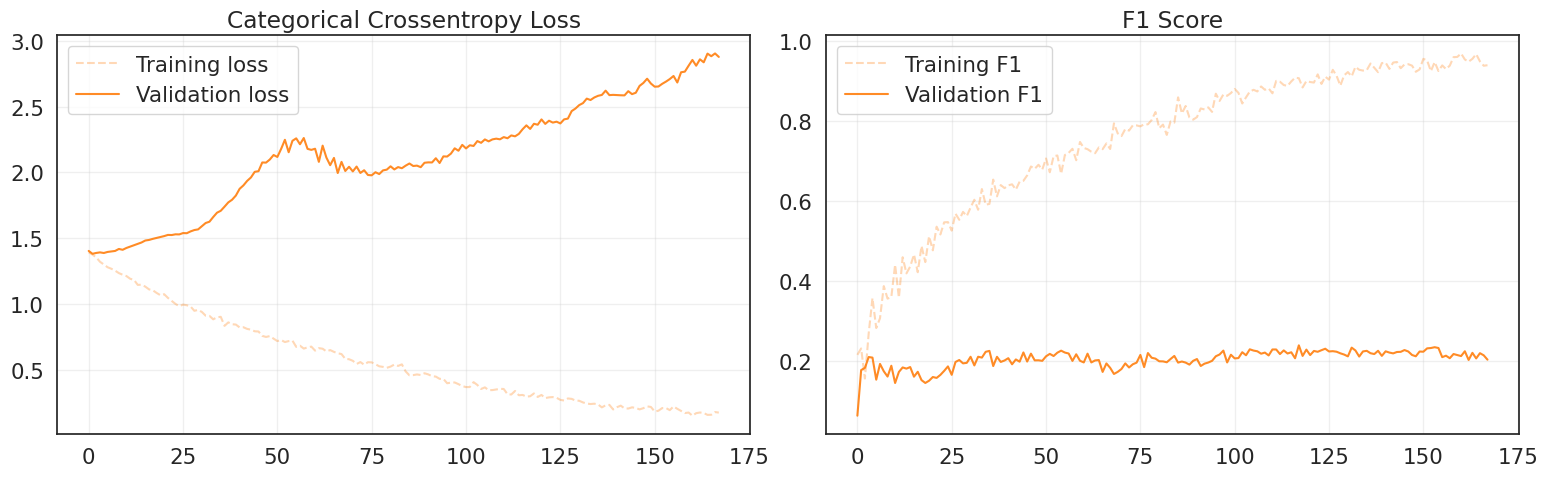

In [98]:
# @title Plot History
# Create a figure with two side-by-side subplots
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(18, 5))

# Plot of training and validation loss on the first axis
ax1.plot(tl_history['train_loss'], label='Training loss', alpha=0.3, color='#ff7f0e', linestyle='--')
ax1.plot(tl_history['val_loss'], label='Validation loss', alpha=0.9, color='#ff7f0e')
ax1.set_title('Categorical Crossentropy Loss')
ax1.legend()
ax1.grid(alpha=0.3)

# Plot of training and validation Accuracy on the second axis
ax2.plot(tl_history['train_f1'], label='Training F1', alpha=0.3, color='#ff7f0e', linestyle='--')
ax2.plot(tl_history['val_f1'], label='Validation F1', alpha=0.9, color='#ff7f0e')
ax2.set_title('F1 Score')
ax2.legend()
ax2.grid(alpha=0.3)

# Adjust the layout and display the plot
plt.tight_layout()
plt.subplots_adjust(right=0.85)
plt.show()

Accuracy over the validation set: 0.2948
Precision over the validation set: 0.3157
Recall over the validation set: 0.2948
F1 score over the validation set: 0.2758
-----------------------------------
CLASSE               ACCURATEZZA
-----------------------------------
Luminal A            10.29%
Luminal B            45.45%
HER2(+)              37.50%
Triple negative      9.68%
-----------------------------------


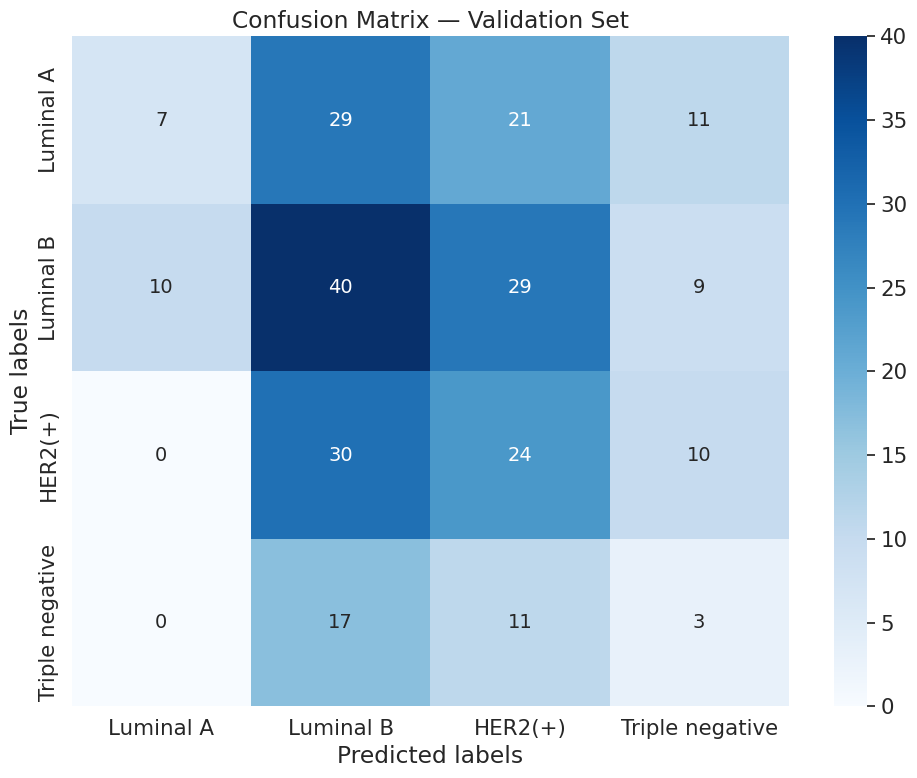

In [99]:
# @title Plot Confusion Matrix
# Collect predictions and ground truth labels
class_labels = ['Luminal A', 'Luminal B', 'HER2(+)', 'Triple negative']

val_preds, val_targets = [], []
with torch.no_grad():  # Disable gradient computation for inference
    for xb, yb in val_loader:
        xb = xb.to(device)

        # Forward pass: get model predictions
        logits = tl_model(xb)
        preds = logits.argmax(dim=1).cpu().numpy()

        # Store batch results
        val_preds.append(preds)
        val_targets.append(yb.numpy())

# Combine all batches into single arrays
val_preds = np.concatenate(val_preds)
val_targets = np.concatenate(val_targets)

# Calculate overall validation metrics
val_acc = accuracy_score(val_targets, val_preds)
val_prec = precision_score(val_targets, val_preds, average='weighted')
val_rec = recall_score(val_targets, val_preds, average='weighted')
val_f1 = f1_score(val_targets, val_preds, average='weighted')
print(f"Accuracy over the validation set: {val_acc:.4f}")
print(f"Precision over the validation set: {val_prec:.4f}")
print(f"Recall over the validation set: {val_rec:.4f}")
print(f"F1 score over the validation set: {val_f1:.4f}")

# Generate confusion matrix for detailed error analysis
cm = confusion_matrix(val_targets, val_preds)

# Create numeric labels for heatmap annotation
labels = np.array([f"{num}" for num in cm.flatten()]).reshape(cm.shape)

# Store accuracy per class with desired names
#Calcola il totale per ogni classe reale (somma delle righe)
true_totals = cm.sum(axis=1)
#Normalizza la matrice (gestendo la divisione per zero)
cm_perc = np.divide(cm.astype(float), true_totals[:, None], out=np.zeros_like(cm, dtype=float), where=true_totals[:, None]>0)
#Estrai la diagonale (che è l'accuratezza per ogni classe)
per_class_accuracy = cm_perc.diagonal()

accuracy_LA = per_class_accuracy[0]
accuracy_LB = per_class_accuracy[1]
accuracy_H2 = per_class_accuracy[2]
accuracy_TN = per_class_accuracy[3]

print("-" * 35)
print(f"{'CLASSE':<20} {'ACCURATEZZA'}")
print("-" * 35)

print(f"{'Luminal A':<20} {accuracy_LA:.2%}")
print(f"{'Luminal B':<20} {accuracy_LB:.2%}")
print(f"{'HER2(+)':<20} {accuracy_H2:.2%}")
print(f"{'Triple negative':<20} {accuracy_TN:.2%}")
print("-" * 35)

# Visualise confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=labels, fmt='',
            cmap='Blues',
            xticklabels=class_labels,
            yticklabels=class_labels
            )
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix — Validation Set')
plt.tight_layout()
plt.show()

## 🕹️ **Use the Model - Make Inference**

In [100]:
#PREPARE DATA FOR TESTING
test_ds = TensorDataset(torch.from_numpy(test_images).permute(0, 3, 1, 2))
test_loader = make_loader(test_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)

In [101]:
# Load the  model for inference
best_model = MobileNetV3TransferLearning(NUM_CLASSES, DROPOUT_RATE, freeze_backbone=True).to(device)
best_model.load_state_dict(torch.load(OUTPUT_DIR/"models"/(EXPERIMENT_NAME+"_model.pt")))
best_model.eval()

print("Model loaded successfully!")

Model loaded successfully!


In [102]:
# Collect predictions and ground truth labels
test_preds = []
with torch.no_grad():  # Disable gradient computation for inference
    for batch in test_loader:

        xb = batch[0].to(device)

        # Forward pass: get model predictions
        logits = best_model(xb)
        preds = logits.argmax(dim=1).cpu().numpy()

        # Store batch results
        test_preds.append(preds)

# Combine all batches into single arrays
test_preds = np.concatenate(test_preds)

#CREAZIONE CSV SUBMISSION
target_to_label = {
    0: 'Luminal A',
    1: 'Luminal B',
    2: 'HER2(+)',
    3: 'Triple negative'
}

#Ricostruisco il nome delle immagini: i=0 -> "img_0000.png", i=10 -> "img_0010.png"
filenames = [f"img_{i:04d}.png" for i in range(len(test_preds))]
predicted_labels = [target_to_label[p] for p in test_preds]

df_results = pd.DataFrame({
    "sample_index": filenames,
    "label": predicted_labels
})

csv_path = OUTPUT_DIR / 'test_predictions.csv'
df_results.to_csv(csv_path, index=False, header=True)
print(f"test_predictions.csv creato e salvato correttamente in: {csv_path}")

test_predictions.csv creato e salvato correttamente in: /kaggle/working/test_predictions.csv
